# Normalising Flow

**Run this notebook:** in Colab, choose **Runtime → Run all**. The first cell prepares METIS automatically using uv; a fresh runtime needs this setup again. These short tutorials use a CPU. Locally, select your [METIS Python environment](https://ojwatson.github.io/metis/basics/installing_metis.html).

The outputs below were generated when the documentation was built. [Source revision `b20b270c079a`](https://github.com/OJWatson/metis/tree/b20b270c079ad27a227a41b67828abcde7c74f87).

In [ ]:
#@title Prepare METIS (run once per runtime)
"""Embedded in notebook downloads: prepare their disposable Colab runtime with uv."""

import importlib
import importlib.metadata
import importlib.util
import io
import json
import os
from pathlib import Path
import platform
import re
import shutil
import subprocess
import sys
import tarfile
import urllib.request


UV_VERSION = "0.7.22"
INSTALL_GUIDE = "https://ojwatson.github.io/metis/basics/installing_metis.html"


def _installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None


def _compatible_pin(package, minimum, maximum=None):
    """Preserve compatible binary libraries already supplied by Colab."""
    version = _installed_version(package)
    if version is None:
        return None
    match = re.match(r"^(\d+)\.(\d+)(?:\.(\d+))?", version)
    if match is None:
        return None
    release = tuple(int(value or 0) for value in match.groups())
    if release < minimum or (maximum is not None and release >= maximum):
        return None
    return f"{package}=={version}"


def _uv_executable(directory):
    installed = shutil.which("uv")
    if installed:
        return installed
    destination = directory / "uv"
    if not destination.exists():
        architecture = {"x86_64": "x86_64", "aarch64": "aarch64"}.get(platform.machine())
        if architecture is None:
            raise RuntimeError(f"Unsupported Colab CPU architecture: {platform.machine()}")
        archive_name = f"uv-{architecture}-unknown-linux-gnu"
        url = (
            f"https://github.com/astral-sh/uv/releases/download/{UV_VERSION}/"
            f"{archive_name}.tar.gz"
        )
        with urllib.request.urlopen(url, timeout=120) as response:
            archive_bytes = response.read()
        with tarfile.open(fileobj=io.BytesIO(archive_bytes), mode="r:gz") as archive:
            # Read one known member, without extracting arbitrary archive paths.
            binary = archive.extractfile(f"{archive_name}/uv")
            if binary is None:
                raise RuntimeError("The uv release archive contains no executable")
            destination.write_bytes(binary.read())
        destination.chmod(0o755)
    return str(destination)


def _project_text(revision):
    dependencies = [
        f"metis-surrogate[plots,pandas] @ git+https://github.com/OJWatson/metis.git@{revision}",
        "torch==2.10.0",
    ]
    for package, minimum, maximum in [
        ("numpy", (2, 0, 0), (3, 0, 0)),
        ("matplotlib", (3, 9, 0), (4, 0, 0)),
        ("pandas", (2, 2, 0), (4, 0, 0)),
        ("pyarrow", (18, 0, 0), None),
        ("polars", (1, 37, 0), (3, 0, 0)),
    ]:
        pin = _compatible_pin(package, minimum, maximum)
        if pin:
            dependencies.append(pin)
    return (
        '[project]\nname = "metis-colab-tutorial"\nversion = "0.0.0"\n'
        f'requires-python = ">={sys.version_info.major}.{sys.version_info.minor},'
        f'<{sys.version_info.major}.{sys.version_info.minor + 1}"\n'
        f"dependencies = {json.dumps(dependencies)}\n\n"
        '[tool.uv]\npackage = false\n\n'
        '[tool.uv.sources]\ntorch = { index = "pytorch-cpu" }\n\n'
        '[[tool.uv.index]]\nname = "pytorch-cpu"\n'
        'url = "https://download.pytorch.org/whl/cpu"\nexplicit = true\n'
    )


def _metis_origin():
    try:
        return importlib.metadata.distribution("metis-surrogate").read_text("direct_url.json")
    except importlib.metadata.PackageNotFoundError:
        return None


def prepare_colab(revision):
    """Install only inside Colab; local notebooks use the selected METIS environment."""
    if not re.fullmatch(r"[a-f0-9]{40}", revision):
        raise ValueError("Notebook setup needs an exact 40-character source revision")
    try:
        in_colab = (
            importlib.util.find_spec("google.colab") is not None
            and bool(os.environ.get("COLAB_RELEASE_TAG") or os.environ.get("COLAB_BACKEND_VERSION"))
        )
    except ModuleNotFoundError:
        in_colab = False
    if not in_colab:
        if _installed_version("metis-surrogate") is None:
            raise RuntimeError(f"Select a Python environment containing METIS: {INSTALL_GUIDE}")
        print(f"Using local METIS {_installed_version('metis-surrogate')}.")
        return
    if sys.version_info < (3, 11):
        raise RuntimeError("This tutorial requires a Colab runtime with Python 3.11 or newer.")

    directory = Path("/content/.metis-notebooks")
    directory.mkdir(parents=True, exist_ok=True)
    (directory / "pyproject.toml").write_text(_project_text(revision), encoding="utf-8")
    loaded = {
        package: str(getattr(sys.modules[package], "__version__", _installed_version(package)))
        for package in ("numpy", "pandas", "torch", "matplotlib", "pyarrow", "polars")
        if package in sys.modules
    }
    metis_was_loaded = "metis" in sys.modules
    previous_metis_origin = _metis_origin()
    if metis_was_loaded:
        # Retain the import's identity if the user reruns setup after a restart
        # warning without actually restarting the Python process.
        previous_metis_origin = sys.modules["metis"].__dict__.setdefault(
            "_notebook_runtime_origin", previous_metis_origin,
        )
    environment = os.environ.copy()
    # Colab is a disposable runtime. Keep its unrelated packages and its active
    # notebook interpreter, instead of adding a second environment to sys.path.
    environment["UV_PROJECT_ENVIRONMENT"] = sys.prefix
    environment.pop("VIRTUAL_ENV", None)
    print("Preparing this Colab runtime with uv (CPU tutorial environment)…")
    result = subprocess.run(
        [_uv_executable(directory), "sync", "--inexact", "--no-dev", "--no-editable",
         "--project", str(directory), "--python", sys.executable],
        env=environment, text=True, capture_output=True,
    )
    if result.returncode:
        raise RuntimeError(f"METIS setup failed:\n{result.stdout}\n{result.stderr}")
    importlib.invalidate_caches()
    changed = [package for package, before in loaded.items() if _installed_version(package) != before]
    if metis_was_loaded and _metis_origin() != previous_metis_origin:
        changed.append("metis")
    if changed:
        raise RuntimeError(
            "Setup updated already-loaded libraries (" + ", ".join(changed) + "). "
            "Choose Runtime > Restart session, then Run all. Setup will reuse its installed packages."
        )
    print(f"METIS {_installed_version('metis-surrogate')} is ready. Continue with the tutorial.")


prepare_colab("b20b270c079ad27a227a41b67828abcde7c74f87")


The normalising flow model is a stochastic surrogate with efficiently computable exact density.

## When this might be a good fit


The normalising flow surrogate is a good option when stochasticity and/or evaluating the exact density of the surrogate is needed. Access to this density enables the surrogate to be used in parameter inference pipelines like MCMC, Variational Inference or Simulation-Based Inference (SBI).

Architecturally it is implemented as a Transformer Autoregressive Flow (TARFlow), which is a modern normalising flow design that composes transformer blocks into an end-to-end invertible architecture. Currently it only supports static inputs. Its density is that of the fitted continuous surrogate, not the exact likelihood of the simulator.

## How Normalising Flows work

### Maximum likelihood via change of variables
A Normalising Flow parametrises an invertible transformation $f_{\theta}$ from the data distribution $p_{\mathrm{data}}$ to a noise distribution $p_0$ (usually Gaussian). Once trained the network can be inverted to transform noise samples into data. This transformation also has an associated density $p_{\mathrm{model}}$ which is accessible via the change of variable formula

$$
\log p_{\mathrm{model}}(x)=\log p_0(f_{\theta}(x))+\log\vert\mathrm{det}(\frac{df_{\theta}(x)}{dx})\vert
$$

Architecturally Normalising Flows are designed to be exactly invertible with log-determinants that can be efficiently computed. This allows a maximum likelihood estimation objective to be implemented as

$$
\min_{\theta}\; -\log p_0(f_{\theta}(x))-\log\vert\mathrm{det}(\frac{df_{\theta}(x)}{dx})\vert
$$


### Architecture

Normalising Flows have a rich literature with architectures that make different tradeoffs and until recently they were not regarded as scalable as generative models. Recently, the Transformer Autoregressive Flow (TARFlow) [@tarflow] has emerged as a scalable approach to Normalising Flows. Like many Normalising Flows the overall network $f_{\theta}$ is a composition of several invertible *blocks* $f_{M}\circ f_{M-1}\cdots\circ f_{1}$. Each of these blocks flips the order of the sequence with $\pi(x)$, and predicts scale $\alpha$ and shift $\mu$ parameters for each of the elements in the sequence with an autoregressive transformer $T(x)$:
$$
\begin{align}
&x^{\mathrm{output}}_{i}=(x^{\mathrm{input}}_{i}-\mu_{i})\odot \exp (-\alpha_i)\\
&\text{where } \mu_i \text{ and } \alpha_i \text{ are predicted by } T(x_{<i})\\
\end{align}
$$

![](https://ojwatson.github.io/metis/models/images/transformer-ar-flow-block.svg){fig-alt="An invertible transformer autoregressive flow block predicts scale and shift."}

Transformer Autoregressive Flow Block. Adapted from @tarflow.

Crucially, since the transformer is causal, $\alpha_i$ and $\mu_i$ only depend on the elements strictly preceding $i$. Hence, the block can be exactly inverted by autoregressively rolling out

$$
x^{\mathrm{input}}_{i}=(x^{\mathrm{output}}_{i}\odot\exp(\alpha_i))+\mu_i
$$


Normalising flows can have numerical difficulties on high-dimensional data.
METIS does not apply the noise augmentation and Tweedie denoising used in the
image experiments of @tarflow. Inspect both samples and held-out densities.



## Configuring an iTARFlow model

Pass architecture options to `Surrogate("itarflow", model_options={...})`:

| Option | Meaning | Default |
|---|---|---:|
| `channels` | Hidden dimension (width) | 64 |
| `num_blocks` | Number of invertible flow blocks | 2 |
| `num_layers` | Transformer layers per flow block | 2 |
| `num_heads` | Number of attention heads | 4 |
| `num_static_tokens` | Tokens encoding the static inputs | 4 |
| `patch_size` | Time points grouped into one token | 1 |

A larger `patch_size` shortens the sequence processed by the model and must
divide the number of time points. Input and output dimensions are inferred
from the bank. Through [Hydra](https://ojwatson.github.io/metis/basics/hydra.html):

```bash
uv run metis train model=itarflow model.model_options.channels=128
```

## Training on SIRDS

We use the same [SIRDS simulations](https://ojwatson.github.io/metis/basics/sirds-example.html) and grouped
train/validation/test split as the [training tutorial](https://ojwatson.github.io/metis/basics/training.html).
This small CPU fit uses 1,000 optimizer steps.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from metis import load_example, Surrogate, TrainingConfig

bank = load_example()
split = bank.split(seed=42)

In [2]:
model = Surrogate(
    "itarflow",
    model_options={"channels": 32, "num_blocks": 2, "num_layers": 1, "num_heads": 2},
).fit(
    split.train, split.validation,
    config=TrainingConfig(steps=1000, batch_size=64, eval_every=100, seed=42),
)

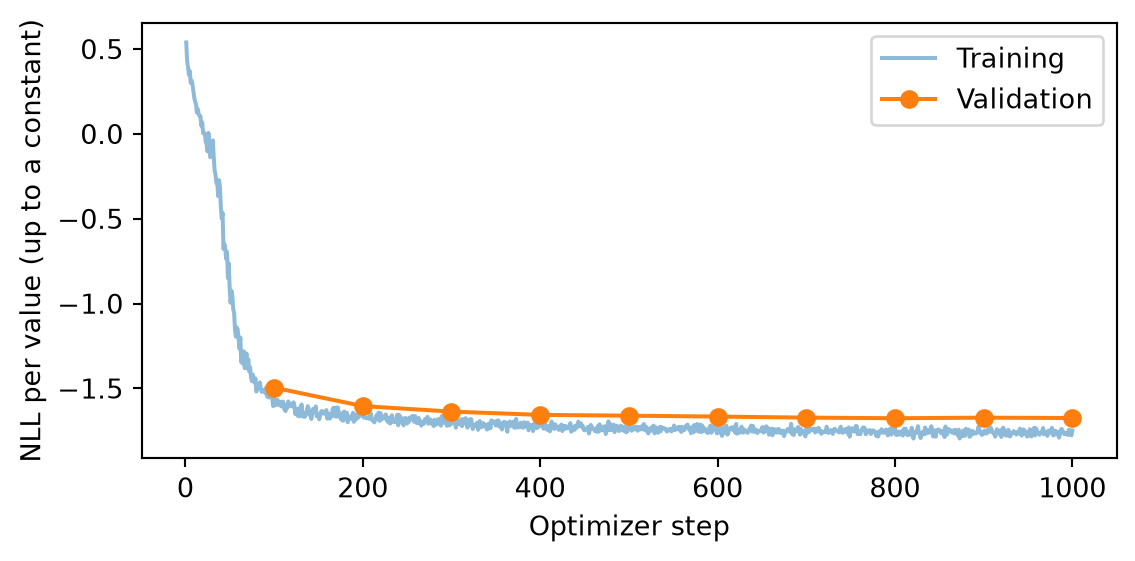

In [3]:
#| code-fold: true
#| code-summary: "Plot training and validation loss"
#| fig-cap: "iTARFlow: training and validation loss for the bundled SIRDS bank."
validation = [row for row in model.history if "validation_loss" in row]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot([row["step"] for row in model.history],
        [row["train_loss"] for row in model.history], alpha=0.5, label="Training")
ax.plot([row["step"] for row in validation],
        [row["validation_loss"] for row in validation], "o-", label="Validation")
ax.set(xlabel="Optimizer step", ylabel="NLL per value (up to a constant)")
ax.legend()
fig.tight_layout()
plt.show()

*iTARFlow: training and validation loss for the bundled SIRDS bank.*

Generate several trajectories for the same held-out inputs by changing the
initial noise. The band below describes variation in surrogate samples, not
uncertainty in fitted model weights.

In [4]:
inputs = split.test.inputs[:1]
draws = model.sample(inputs, n_samples=100, seed=13)[0]
print("Samples × times × outputs:", draws.shape)
print(f"Smallest generated compartment count: {draws.min():.1f}")

Samples × times × outputs: (100, 40, 4)
Smallest generated compartment count: -486.8


/home/runner/work/metis/metis/src/metis/surrogate.py:737: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  array = self._inputs(inputs)


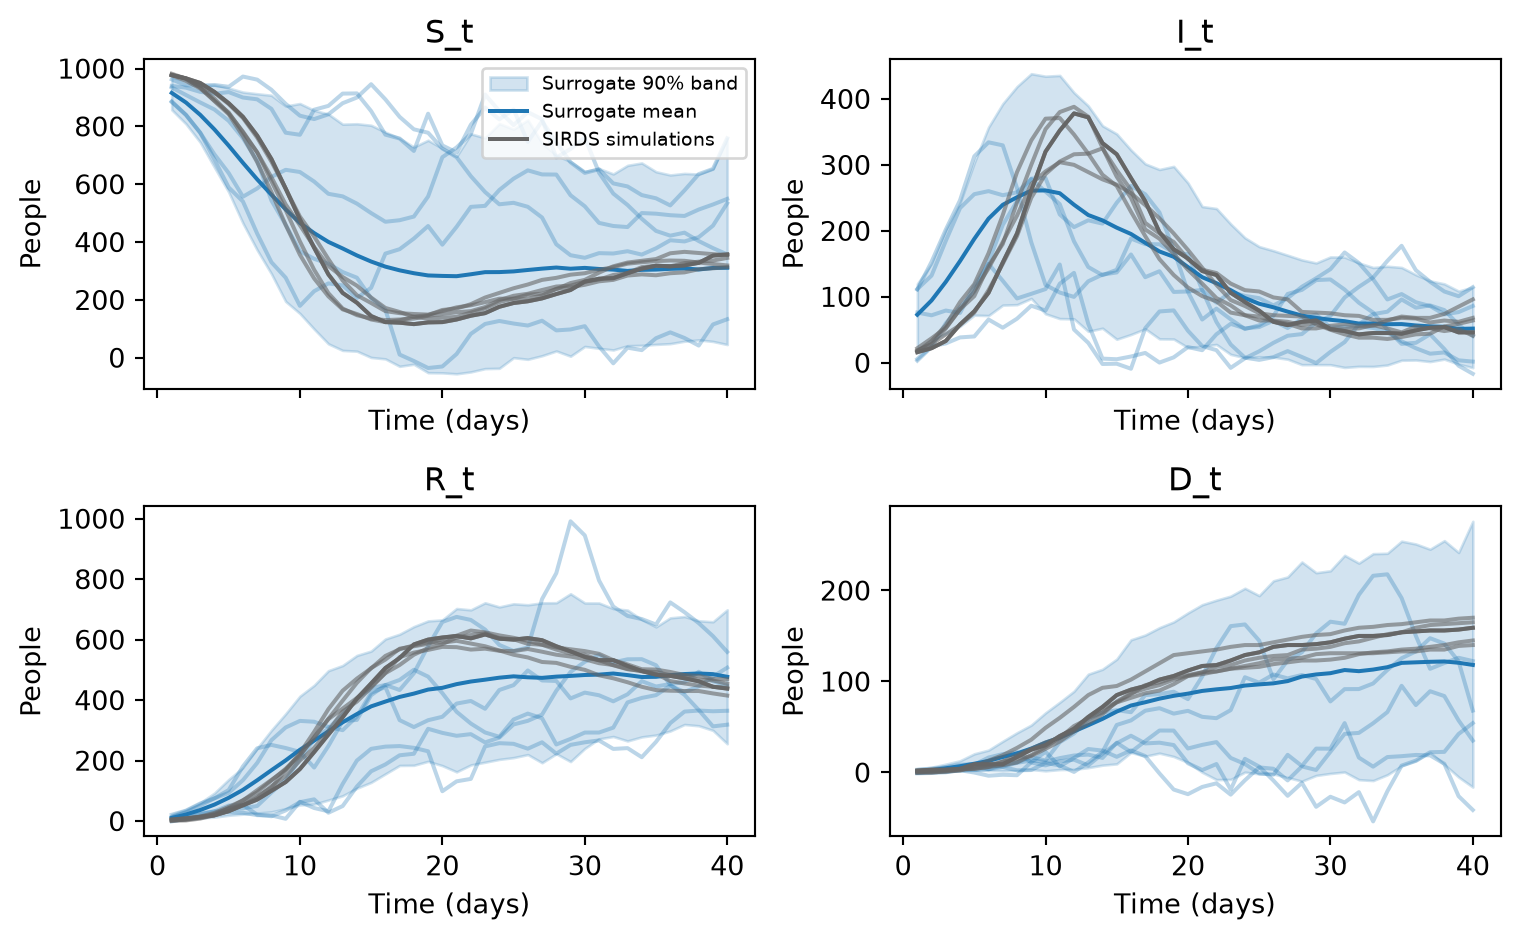

In [5]:
#| code-fold: true
#| code-summary: "Compare surrogate samples with SIRDS simulations"
#| fig-cap: "iTARFlow: generated trajectories and five SIRDS simulations at the first held-out parameter setting. Shading spans the pointwise 5th–95th percentiles of 100 surrogate draws, after fitting the bundled SIRDS training split."
same_inputs = np.all(split.test.inputs == inputs[0], axis=1)
replicates = split.test.outputs[same_inputs]
low, high = np.quantile(draws, [0.05, 0.95], axis=0)
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True)
for channel, ax in enumerate(axes.flat):
    ax.fill_between(bank.times, low[:, channel], high[:, channel],
                    color="C0", alpha=0.2, label="Surrogate 90% band")
    ax.plot(bank.times, draws[:5, :, channel].T, color="C0", alpha=0.3)
    ax.plot(bank.times, draws.mean(axis=0)[:, channel], color="C0", label="Surrogate mean")
    ax.plot(bank.times, replicates[:, :, channel].T, color="0.4", alpha=0.6)
    ax.plot(bank.times, replicates[0, :, channel], color="0.4", label="SIRDS simulations")
    ax.set(title=bank.output_names[channel], xlabel="Time (days)", ylabel="People")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

*iTARFlow: generated trajectories and five SIRDS simulations at the first held-out parameter setting. Shading spans the pointwise 5th–95th percentiles of 100 surrogate draws, after fitting the bundled SIRDS training split.*

This short fit generates much wider variation than the SIRDS simulations,
including negative counts. It is not yet a faithful SIRDS surrogate. Check
samples and performance across the whole held-out bank, as in the
[training tutorial](https://ojwatson.github.io/metis/basics/training.html); a density value alone does not
establish a good fit.

The flow can also evaluate the log density of a held-out trajectory, in the
original output units:

In [6]:
log_density = model.log_prob(inputs, split.test.outputs[:1])
print("Held-out log density:", log_density[0])

Held-out log density: -603.8782315902378


/home/runner/work/metis/metis/src/metis/surrogate.py:849: UserWarning: Inputs outside the training ranges for ['I_0']; predictions extrapolate and are not clipped.
  self.log_prob_tensor(


SIRDS outputs are integer counts with a fixed population total. A continuous
flow approximates these outputs; its density is not the probability of an
integer trajectory. See [surrogate likelihoods](https://ojwatson.github.io/metis/sbi/vi-mcmc.html) before
using this quantity for inference.